# Experimentos preliminares de modelado
**Proyecto I — Uso problemático de internet en niños y adolescentes**

Este cuaderno compara unos pocos modelos sencillos sobre los registros con etiqueta (`sii`) de `df_eda_completo.csv`, con el fin de responder, de forma preliminar, la pregunta del proyecto: *¿qué tanto se puede estimar el nivel de severidad con datos fáciles de medir, y cuánto mejora esto frente a un modelo de referencia?*

**Qué es y qué no es.** Son resultados exploratorios para orientar las decisiones del equipo: no hay ajuste fino de hiperparámetros ni un conjunto de prueba independiente (el `test.csv` de Kaggle no trae etiquetas). Las cifras son estimaciones por validación cruzada y deben leerse con su variabilidad.

## 1. Datos y conjuntos de variables
- Se usan solo los registros con `sii` (2.736).
- Se **excluyen** las 22 columnas PCIAT (el target se calcula a partir de ellas), el `id`, las columnas de temporada (`*-Season`) y las del CGAS (una valoración que hace un clínico, que no es de fácil medición).
- Los valores imposibles (ceros en IMC, peso y presión arterial) se pasan a `NaN`.
- Cuatro conjuntos de variables, de menos a más:

| Conjunto | Contenido |
|---|---|
| **A** | edad y sexo |
| **B** | A + medidas físicas, de aptitud, bioimpedancia, actividad (PAQ) y sueño (SDS) |
| **C** | B + horas de internet (tiempo de pantalla) |
| **D** | C + las 7 variables del acelerómetro |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (cohen_kappa_score, f1_score, accuracy_score, recall_score,
                             roc_auc_score, balanced_accuracy_score, make_scorer)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

df = pd.read_csv("df_eda_completo.csv")
lab = df[df["sii"].notna()].copy()
lab["sii"] = lab["sii"].astype(int)
for c in ["Physical-BMI", "Physical-Weight", "Physical-Diastolic_BP", "Physical-Systolic_BP"]:
    lab.loc[lab[c] <= 0, c] = np.nan

excluir = [c for c in lab.columns
           if c.startswith("PCIAT") or c.startswith("CGAS") or ("Season" in c) or c in ("id", "sii")]
base = ["Basic_Demos-Age", "Basic_Demos-Sex"]
horas = ["PreInt_EduHx-computerinternet_hoursday"]
reloj = ["enmo_general_semana", "enmo_general_fin_de_semana", "enmo_madrugada", "enmo_libre",
         "anglez_madrugada", "light_dia", "light_madrugada"]
candidatas = [c for c in lab.columns if c not in excluir]
fisicas_sueno = [c for c in candidatas if c not in base + horas + reloj]
conjuntos = {
    "A": base,
    "B": base + fisicas_sueno,
    "C": base + fisicas_sueno + horas,
    "D": base + fisicas_sueno + horas + reloj,
}
print("Registros:", len(lab))
print({k: len(v) for k, v in conjuntos.items()}, "variables por conjunto")
y = lab["sii"].values


Registros: 2736
{'A': 2, 'B': 46, 'C': 47, 'D': 54} variables por conjunto


## 2. Protocolo de evaluación
- **Validación cruzada estratificada de 5 particiones, repetida 3 veces** (15 evaluaciones por modelo). Se reporta el promedio y la desviación estándar entre particiones.
- Todo el preprocesamiento (imputación, escalado) está **dentro del pipeline**, de modo que se aprende solo con los datos de entrenamiento de cada partición.
- **Métricas:** kappa cuadrático ponderado (QWK, la métrica de la competencia: tiene en cuenta que los niveles están ordenados), F1 macro, exactitud y *recall* de los niveles moderado y severo (2 y 3 juntos).
- **Modelos:** mayoritaria (siempre predice 0), regresión logística regularizada, *gradient boosting* con histogramas (acepta faltantes) y bosque aleatorio. Los modelos usan pesos de clase balanceados para no ignorar las clases pequeñas.

In [2]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
particiones = list(cv.split(lab, y))


def modelo_logistico():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"))


def modelo_boosting():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                          class_weight="balanced", random_state=42)


def modelo_bosque():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                class_weight="balanced_subsample", random_state=42, n_jobs=-1))


def modelo_mayoritaria():
    return DummyClassifier(strategy="most_frequent")


def metricas(yt, yp):
    return {"QWK": cohen_kappa_score(yt, yp, weights="quadratic"),
            "F1 macro": f1_score(yt, yp, average="macro"),
            "Exactitud": accuracy_score(yt, yp),
            "Recall niveles 2-3": recall_score(np.isin(yt, [2, 3]), np.isin(yp, [2, 3]))}


def evaluar(fabrica, columnas, datos=None, objetivo=None):
    datos = lab if datos is None else datos
    objetivo = y if objetivo is None else objetivo
    X = datos[columnas]
    filas = []
    divisiones = particiones if datos is lab else list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(datos, objetivo))
    for tr, te in divisiones:
        m = fabrica()
        m.fit(X.iloc[tr], objetivo[tr])
        filas.append(metricas(objetivo[te], m.predict(X.iloc[te])))
    return pd.DataFrame(filas)


experimentos = [
    ("Mayoritaria (siempre 0)", "—", modelo_mayoritaria, "A"),
    ("Regresión logística", "A", modelo_logistico, "A"),
    ("Regresión logística", "B", modelo_logistico, "B"),
    ("Regresión logística", "C", modelo_logistico, "C"),
    ("Regresión logística", "D", modelo_logistico, "D"),
    ("Gradient boosting", "A", modelo_boosting, "A"),
    ("Gradient boosting", "B", modelo_boosting, "B"),
    ("Gradient boosting", "C", modelo_boosting, "C"),
    ("Gradient boosting", "D", modelo_boosting, "D"),
    ("Bosque aleatorio", "C", modelo_bosque, "C"),
]
resumen, por_particion = [], {}
for nombre, conj, fabrica, clave in experimentos:
    r = evaluar(fabrica, conjuntos[clave])
    por_particion[(nombre, conj)] = r
    fila = {"Modelo": nombre, "Variables": conj}
    for m in r.columns:
        fila[m] = f"{r[m].mean():.3f} ± {r[m].std():.3f}"
        fila[m + "_media"] = r[m].mean()
        fila[m + "_sd"] = r[m].std()
    resumen.append(fila)
res4 = pd.DataFrame(resumen)
display(res4[["Modelo", "Variables", "QWK", "F1 macro", "Exactitud", "Recall niveles 2-3"]])


,Modelo,Variables,QWK,F1 macro,Exactitud,Recall niveles 2-3
0,Mayoritaria (siempre 0),—,0.000 ± 0.000,0.184 ± 0.000,0.583 ± 0.001,0.000 ± 0.000
1,Regresión logística,A,0.321 ± 0.032,0.316 ± 0.020,0.496 ± 0.021,0.604 ± 0.060
2,Regresión logística,B,0.350 ± 0.034,0.358 ± 0.022,0.503 ± 0.019,0.597 ± 0.039
3,Regresión logística,C,0.379 ± 0.031,0.373 ± 0.022,0.523 ± 0.016,0.605 ± 0.047
4,Regresión logística,D,0.372 ± 0.036,0.371 ± 0.025,0.525 ± 0.019,0.590 ± 0.056
5,Gradient boosting,A,0.291 ± 0.029,0.285 ± 0.019,0.449 ± 0.026,0.623 ± 0.063
6,Gradient boosting,B,0.358 ± 0.050,0.359 ± 0.036,0.528 ± 0.024,0.436 ± 0.057
7,Gradient boosting,C,0.386 ± 0.050,0.370 ± 0.037,0.542 ± 0.021,0.453 ± 0.057
8,Gradient boosting,D,0.381 ± 0.052,0.375 ± 0.038,0.547 ± 0.020,0.446 ± 0.045
9,Bosque aleatorio,C,0.402 ± 0.032,0.382 ± 0.033,0.564 ± 0.020,0.387 ± 0.031


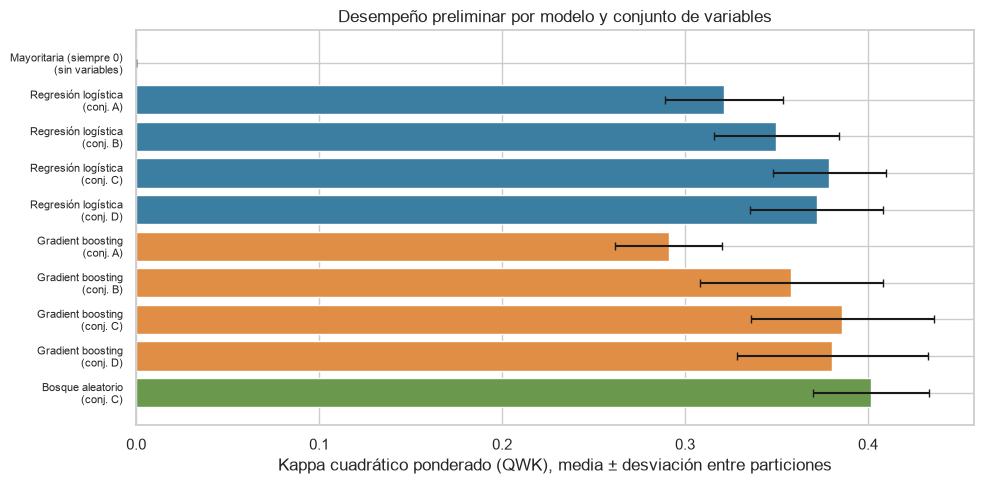

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
etq = [f"{r.Modelo}\n({'conj. ' + r.Variables if r.Variables != '—' else 'sin variables'})" for r in res4.itertuples()]
colores = ["#bdbdbd"] + ["#3b7ea1"] * 4 + ["#e08e45"] * 4 + ["#6a994e"]
ax.barh(range(len(res4))[::-1], res4["QWK_media"], xerr=res4["QWK_sd"], color=colores, capsize=3)
ax.set_yticks(range(len(res4))[::-1])
ax.set_yticklabels(etq, fontsize=8)
ax.set_xlabel("Kappa cuadrático ponderado (QWK), media ± desviación entre particiones")
ax.set_title("Desempeño preliminar por modelo y conjunto de variables")
plt.tight_layout()
plt.show()


El modelo de referencia, que siempre predice el nivel 0, acierta el 58,3 % de las veces pero tiene un QWK de 0: no ordena a nadie. Con solo la edad y el sexo, la regresión logística ya llega a un QWK de 0,32, es decir que buena parte de lo que se logra viene de la edad. Al sumar las medidas físicas y de sueño (conjunto B) sube a 0,35, y al agregar las horas de internet (conjunto C) a 0,38.

Los tres modelos del conjunto C quedan muy parecidos (0,38 a 0,40) y la diferencia entre ellos es menor que la variación entre particiones (de ±0,03 a ±0,05), por lo cual no se puede decir que uno sea mejor que otro. Lo que sí cambia es lo que hace cada uno: la regresión logística con pesos balanceados detecta cerca del 60 % de los casos moderados o severos pero acierta menos en general (exactitud 0,52), mientras que el bosque aleatorio acierta más (0,56) y detecta solo el 39 % de esos casos.

## 3. ¿Qué aporta cada grupo de variables más allá de la edad?
La comparación clave es **conjunto A (edad y sexo) frente a los demás**, con el mismo modelo, porque la edad ya explica buena parte de la severidad. Se calcula la diferencia de QWK por partición (las mismas particiones para ambos), para ver si la mejora es consistente.

In [4]:
def mejora(nombre, conj_a, conj_b):
    a = por_particion[(nombre, conj_a)]["QWK"].values
    b = por_particion[(nombre, conj_b)]["QWK"].values
    d = b - a
    return {"Modelo": nombre, "Comparación": f"{conj_b} frente a {conj_a}",
            "Mejora media de QWK": d.mean(), "Particiones con mejora": f"{(d > 0).sum()} de {len(d)}"}

comp = pd.DataFrame([mejora("Regresión logística", "A", "B"), mejora("Regresión logística", "B", "C"),
                     mejora("Regresión logística", "C", "D"), mejora("Regresión logística", "A", "C"),
                     mejora("Gradient boosting", "B", "C"), mejora("Gradient boosting", "C", "D"),
                     mejora("Gradient boosting", "A", "C")])
display(comp.round(3))


,Modelo,Comparación,Mejora media de QWK,Particiones con mejora
0,Regresión logística,B frente a A,0.029,14 de 15
1,Regresión logística,C frente a B,0.029,13 de 15
2,Regresión logística,D frente a C,-0.007,5 de 15
3,Regresión logística,C frente a A,0.058,15 de 15
4,Gradient boosting,C frente a B,0.028,13 de 15
5,Gradient boosting,D frente a C,-0.005,9 de 15
6,Gradient boosting,C frente a A,0.095,15 de 15


Comparando las mismas particiones, pasar de edad y sexo a todas las variables con horas de internet mejora el QWK en 0,058 con regresión logística y en 0,095 con gradient boosting, y la mejora aparece en las 15 particiones. Cada paso ayuda poco (cerca de 0,03). Agregar las variables del acelerómetro no mejora nada: la diferencia es levemente negativa (−0,007 y −0,005).

## 4. Versión binaria del problema (0 frente a 1 o más)
Dado que el nivel 3 tiene muy pocos casos, se evalúa también la pregunta más simple: ¿tiene el menor algún nivel de riesgo (`sii` ≥ 1)? Se reporta el AUC (probabilidad de ordenar bien un par de casos) y la exactitud balanceada.

In [5]:
yb = (y >= 1).astype(int)
filas = []
for nombre, fabrica, conj in [("Mayoritaria", modelo_mayoritaria, "A"), ("Regresión logística", modelo_logistico, "A"),
                              ("Regresión logística", modelo_logistico, "C"), ("Gradient boosting", modelo_boosting, "C")]:
    X = lab[conjuntos[conj]]
    aucs, bas = [], []
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X, yb):
        m = fabrica(); m.fit(X.iloc[tr], yb[tr])
        p = m.predict_proba(X.iloc[te])[:, 1]
        aucs.append(roc_auc_score(yb[te], p) if nombre != "Mayoritaria" else 0.5)
        bas.append(balanced_accuracy_score(yb[te], m.predict(X.iloc[te])))
    filas.append({"Modelo": nombre, "Variables": conj, "AUC": f"{np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f}",
                  "Exactitud balanceada": f"{np.mean(bas):.3f} ± {np.std(bas, ddof=1):.3f}",
                  "AUC_media": np.mean(aucs), "BA_media": np.mean(bas)})
bin_res = pd.DataFrame(filas)
display(bin_res[["Modelo", "Variables", "AUC", "Exactitud balanceada"]])
print("Proporción de clase positiva (sii >= 1):", round(yb.mean(), 3))


,Modelo,Variables,AUC,Exactitud balanceada
0,Mayoritaria,A,0.500 ± 0.000,0.500 ± 0.000
1,Regresión logística,A,0.717 ± 0.025,0.674 ± 0.020
2,Regresión logística,C,0.759 ± 0.022,0.695 ± 0.020
3,Gradient boosting,C,0.751 ± 0.023,0.686 ± 0.019


Proporción de clase positiva (sii >= 1): 0.417


Para la pregunta más simple, si el menor tiene algún nivel de riesgo (`sii` de 1 o más), el AUC es 0,72 usando solo edad y sexo y sube a 0,76 con todas las variables y las horas de internet (regresión logística). Es una mejora real pero modesta.

## 5. Subconjunto con acelerómetro
Solo 996 menores tienen datos del reloj. En el conjunto D completo, las variables del reloj se rellenan para los demás; para saber si realmente aportan, se evalúa **solo entre quienes tienen reloj**, comparando C (sin reloj) con D (con reloj).

In [6]:
sub = lab[lab["enmo_general_semana"].notna()].reset_index(drop=True)
ysub = sub["sii"].values
print("Menores con reloj:", len(sub), "| distribución de sii:", dict(pd.Series(ysub).value_counts().sort_index()))
filas = []
for conj in ["A", "C", "D"]:
    r = evaluar(modelo_logistico, conjuntos[conj], datos=sub, objetivo=ysub)
    filas.append({"Modelo": "Regresión logística", "Variables": conj, "n": len(sub),
                  "QWK": f"{r['QWK'].mean():.3f} ± {r['QWK'].std():.3f}",
                  "F1 macro": f"{r['F1 macro'].mean():.3f} ± {r['F1 macro'].std():.3f}",
                  "QWK_media": r["QWK"].mean()})
sub_res = pd.DataFrame(filas)
display(sub_res[["Modelo", "Variables", "n", "QWK", "F1 macro"]])


Menores con reloj: 996 | distribución de sii: {0: np.int64(583), 1: np.int64(266), 2: np.int64(137), 3: np.int64(10)}


,Modelo,Variables,n,QWK,F1 macro
0,Regresión logística,A,996,0.283 ± 0.053,0.289 ± 0.025
1,Regresión logística,C,996,0.314 ± 0.050,0.342 ± 0.021
2,Regresión logística,D,996,0.313 ± 0.039,0.332 ± 0.022


Entre los 996 menores que tienen reloj, agregar las variables del acelerómetro no mejora el resultado (QWK de 0,313 con reloj frente a 0,314 sin él). Con estos datos y con el resumen por promedios que se hizo, el reloj no aporta información adicional a lo que ya dicen la edad, el sueño y las horas de pantalla.

## 6. ¿Qué variables usa el modelo? (importancia por permutación)
Se entrena el *gradient boosting* con el conjunto C y se mide cuánto cae el QWK en datos no vistos al desordenar cada variable. Valores mayores = el modelo depende más de esa variable. Es una medida de **uso por el modelo**, no de causalidad.

,variable,caida_QWK
0,PreInt_EduHx-computerinternet_hoursday,0.0656
1,Basic_Demos-Age,0.0642
2,SDS-SDS_Total_Raw,0.0585
3,Physical-Weight,0.0183
4,Basic_Demos-Sex,0.0145
5,FGC-FGC_CU,0.0084
6,BIA-BIA_BMC,0.0063
7,FGC-FGC_PU,0.0061
8,Physical-HeartRate,0.0053
9,Physical-Height,0.0051


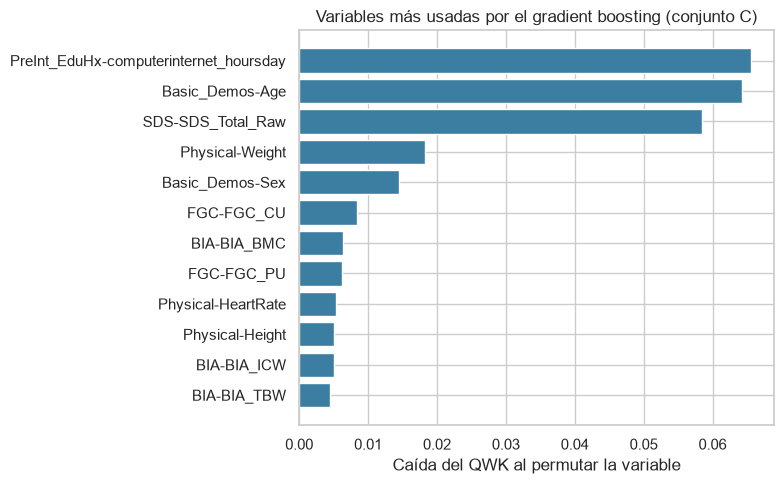

In [7]:
qwk = make_scorer(cohen_kappa_score, weights="quadratic")
Xc = lab[conjuntos["C"]]
imps = []
for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=42).split(Xc, y):
    m = modelo_boosting().fit(Xc.iloc[tr], y[tr])
    pi = permutation_importance(m, Xc.iloc[te], y[te], scoring=qwk, n_repeats=5, random_state=42, n_jobs=1)
    imps.append(pi.importances_mean)
imp = pd.DataFrame({"variable": Xc.columns, "caida_QWK": np.mean(imps, axis=0)}).sort_values("caida_QWK", ascending=False)
top = imp.head(12)
display(top.round(4).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["variable"][::-1], top["caida_QWK"][::-1], color="#3b7ea1")
ax.set_xlabel("Caída del QWK al permutar la variable")
ax.set_title("Variables más usadas por el gradient boosting (conjunto C)")
plt.tight_layout()
plt.show()


Las tres variables que más usa el modelo son las horas de internet, la edad y el puntaje de sueño: al desordenar cualquiera de ellas el QWK cae cerca de 0,06. La siguiente (el peso, que en buena parte refleja la edad) cae 0,018, y las pruebas físicas aparecen más abajo con aportes pequeños. Esta medida dice qué usa el modelo, no qué causa el problema.

## 7. Conclusiones preliminares
1. Hay señal, pero modesta: el QWK queda entre 0,38 y 0,40 y, en la versión binaria, el AUC en 0,76.
2. La edad explica una parte importante de lo que se logra. Con solo edad y sexo ya se llega a 0,32 de QWK.
3. Lo que más suma por encima de la edad son el sueño y las horas de pantalla. Las medidas físicas aportan poco y las variables del acelerómetro, en esta forma de resumirlas, no aportan.
4. Los modelos sencillos rinden parecido entre sí; la elección depende de qué se quiere cuidar más (detectar casos moderados y severos o acertar en general).
5. Los resultados son de validación cruzada sobre una sola base, sin ajuste fino de parámetros y sin un conjunto de prueba independiente. El nivel 3 tiene solo 34 casos, así que no se puede evaluar bien por separado.